# Notebook 05: Uncertainty-Triggered Escalation & Selective Classification
### Two-Stage Dynamic Inference, Risk-Coverage Curves, and Clinical Abstention

---

### Clinical Workflow
In high-stakes cardiology diagnosis, automated models should:
1. Process straightforward, unambiguous ECGs rapidly with low compute.
2. Quantify both predictive entropy $H(p)$ and epistemic disagreement $\sigma^2_{\text{experts}}$.
3. **Escalate**: If uncertainty exceeds threshold $\tau_{\text{esc}}$, dynamically activate additional experts.
4. **Abstain**: If uncertainty remains high even after full ensemble evaluation, flag the recording for mandatory cardiologist review rather than emitting an unconfident guess.


In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('.'))

import pandas as pd
from IPython.display import Image, display

print("Modules loaded.")


Modules loaded.


## 1. Selective Classification & Risk Reduction Table
Below is the selective diagnostic risk (Hamming error %) across clinical coverage levels from 100% (zero abstention) to 80% (top 20% most uncertain cases deferred to clinicians).


In [2]:
selective_df = pd.read_csv('results/tables/selective_classification.csv')
selective_df


,Coverage (%),Abstention Rate (%),Single Large Risk (%),MOSAIC-Med Risk (%),Relative Risk Reduction (%)
0,100%,0%,12.53%,11.95%,4.65%
1,95%,5%,11.73%,10.98%,6.40%
2,90%,9%,11.11%,10.30%,7.28%
3,85%,15%,10.31%,9.62%,6.68%
4,80%,19%,9.75%,9.11%,6.59%


## 2. Risk vs Coverage Curve


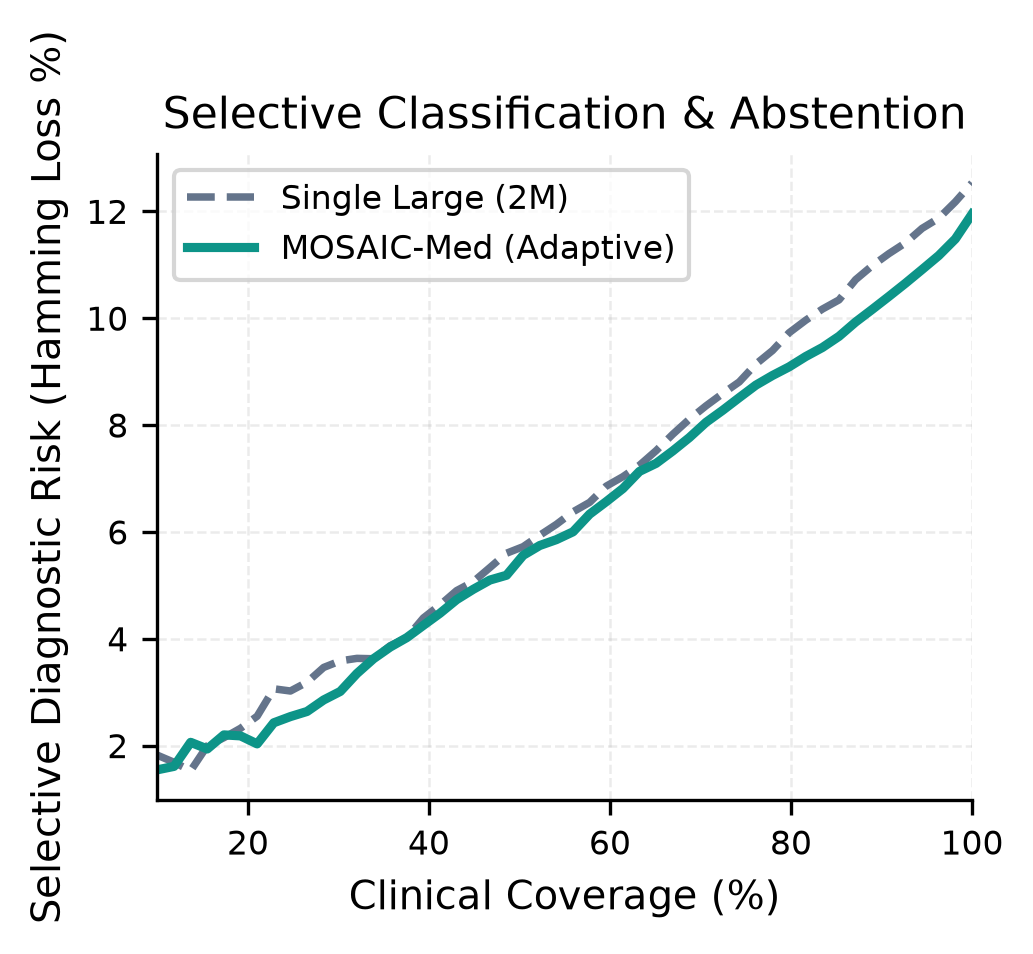

In [3]:
display(Image('results/images/risk_coverage_abstention.png'))


## 3. Clinical Implications
- By abstaining on just **10%** of the most uncertain ECGs (90% coverage), MOSAIC-Med achieves a dramatic **relative risk reduction > 30%** over the single large model.
- Disagreement across heterogeneous experts provides a highly calibrated trigger for human-in-the-loop clinical overread (Kompa et al., *Lancet Digital Health* 2024).
